# The Montego Bay pipeline: figures for article A3

Article A3 in `PLAN_STORIES.md` tells the story of the ships that landed captives at
Montego Bay from 1763 to 1808, most of them from the Bight of Biafra, and of the
north-western parishes where the Christmas Rebellion began in December 1831.

Notebook 06 made the comparison with Kingston using imputed numbers. Imputed fields are
CC BY-NC 4.0, and a newspaper is a commercial publisher, so this notebook works out each
figure for print **from recorded values only**: places, dates and counts as the sources
give them. Imputed figures appear once, labelled, for context. Every number in
`docs/stories/a3_fact_sheet.md` (F1–F19) is asserted at the end.

Needs the full data and the Enslaved.org source (for the runaway notices):
`uv run voyages fetch && uv run voyages fetch -d enslaved && uv run voyages build`.

**What the regions cover.** These are SlaveVoyages' regions of purchase, named for the
coast:

- **Bight of Biafra**: the Niger delta and the Cross River (Bonny, New Calabar, Old
  Calabar: Igbo and Ibibio country, today south-eastern Nigeria), and also the Cameroon
  coast, the Gabon estuary and the Gulf of Guinea islands.
- **West Central Africa**: the coast south of the equator, from Mayumba to Benguela (the
  Loango coast, Kongo and Angola: today southern Gabon, the Republic of Congo, Cabinda, the
  DR Congo coast and Angola). Not Cameroon.
- **Gold Coast**: today's Ghana. **Bight of Benin**: today's Togo, Benin and south-western
  Nigeria. **Upper Guinea**: Senegambia, Sierra Leone and the Windward Coast (Senegal to
  Côte d'Ivoire).

In [1]:
import math

import matplotlib.pyplot as plt
import pandas as pd

import voyages
from voyages import Voyages

v = Voyages()

REGION = {
    "Bight of Biafra and Gulf of Guinea islands": "Bight of Biafra",
    "Gold Coast": "Gold Coast",
    "West Central Africa and St. Helena": "West Central Africa",
    "Bight of Benin": "Bight of Benin",
    "Senegambia and offshore Atlantic": "Upper Guinea",
    "Sierra Leone": "Upper Guinea",
    "Windward Coast": "Upper Guinea",
}
ORDER = [
    "Bight of Biafra",
    "Gold Coast",
    "West Central Africa",
    "Bight of Benin",
    "Upper Guinea",
    "Other or not recorded",
]
PORTS = ["Kingston", "Montego Bay"]

## Recorded voyages to Kingston and Montego Bay

Recorded principal place of landing, recorded principal region of purchase, recorded year
of first landing, and the recorded number of captives landed at the first place of landing.

In [2]:
recorded = (
    v.transatlantic.recorded_only()
    .disembarked_in(*PORTS)
    .to_pandas(["voyage_id", "disembarkation_place_name", "embarkation_region_name"])
    .merge(
        v.sql(
            """
            SELECT voyage_id, ship_name, first_landing_year AS year,
                   captives_arrived_first_landing AS landed,
                   departure_place_name AS home_port
            FROM voyages_wide WHERE dataset = 'transatlantic'
            """
        ).to_pandas(),
        on="voyage_id",
    )
    .rename(columns={"disembarkation_place_name": "port"})
)
recorded["region"] = pd.Categorical(
    recorded.embarkation_region_name.map(REGION).fillna("Other or not recorded"), ORDER
)
window = recorded[recorded.year.between(1763, 1808)]
montego = window[window.port == "Montego Bay"]
window.groupby("port").agg(
    voyages=("voyage_id", "size"),
    with_region=("embarkation_region_name", "count"),
    with_count=("landed", "count"),
    people_landed=("landed", "sum"),
    first=("year", "min"),
    last=("year", "max"),
)

,voyages,with_region,with_count,people_landed,first,last
port,,,,,,
Kingston,944,857,921,282657,1763,1808
Montego Bay,142,132,132,39700,1763,1808


The comparison keeps to voyages with a recorded year in 1763–1808. Two Montego Bay voyages
have no recorded year, so the headline total uses every Montego Bay voyage in the database:

In [3]:
all_montego = recorded[recorded.port == "Montego Bay"]
mb_voyages = len(all_montego)
mb_with_count = int(all_montego.landed.notna().sum())
mb_people = int(all_montego.landed.sum())
mb_no_year = int(all_montego.year.isna().sum())
mb_voyages, mb_with_count, mb_people, mb_no_year

(144, 133, 40050, 2)

## Where they came from

Share of people landed, by recorded region of purchase, among voyages with both a recorded
region and a recorded count.

In [4]:
known = window.dropna(subset=["landed", "embarkation_region_name"])
people = (
    known.pivot_table(
        index="port", columns="region", values="landed", aggfunc="sum", observed=False
    )
    .reindex(PORTS)
    .fillna(0)
    .astype(int)
)  # fmt: skip
mix = (people.div(people.sum(axis=1), axis=0) * 100).round(1)
mix.assign(people=people.sum(axis=1), voyages=known.groupby("port").size())

region,Bight of Biafra,Gold Coast,West Central Africa,Bight of Benin,Upper Guinea,Other or not recorded,people,voyages
port,,,,,,,,
Kingston,36.1,25.8,22.4,8.0,7.3,0.4,263589,835
Montego Bay,71.3,14.6,0.0,3.3,10.8,0.0,38182,124


On recorded figures alone, 71% of the people landed at Montego Bay had been bought in the
Bight of Biafra, against 36% at Kingston. Notebook 06, using imputed figures, gave 68% and
35%. Kingston took a fifth of its people from West Central Africa; Montego Bay none.

The African ports and the British home ports of the Montego Bay ships, recorded:

In [5]:
african_ports = (
    v.sql(
        """
        SELECT principal_purchase_place_name AS african_port,
               count(*) AS voyages, sum(captives_arrived_first_landing) AS landed
        FROM voyages_wide
        WHERE dataset = 'transatlantic' AND principal_landing_place_name = 'Montego Bay'
          AND principal_purchase_place_name IS NOT NULL
        GROUP BY 1 ORDER BY landed DESC NULLS LAST LIMIT 6
        """
    )
    .to_pandas()
    .set_index("african_port")
)
african_ports

,voyages,landed
african_port,,
Bonny,53,20138.0
New Calabar,14,3825.0
"Anomabu, Adja, Agga",10,2384.0
Calabar,9,1809.0
Cape Coast Castle,5,1572.0
Cape Mount (Cape Grand Mount),7,1418.0


Within the Bight of Biafra, which part of the coast? Montego Bay voyages with a recorded
place of purchase in the region, grouped by today's country:

In [6]:
NIGERIA = {"Bonny", "New Calabar", "Calabar", "Andony", "River Brass", "Formosa"}
CAMEROON = {"River del Rey", "Bimbia", "Cameroons", "Cameroons River"}
GABON = {"Gabon", "Cap Lopez", "Rio Nazareth", "Corisco"}
biafra_ports = v.sql(
    """
    SELECT w.principal_purchase_place_name AS port,
           w.captives_arrived_first_landing AS landed
    FROM voyages_wide w
    JOIN places p ON p.code = w.principal_purchase_place
    JOIN places r ON r.code = p.region_code
    WHERE w.dataset = 'transatlantic' AND w.principal_landing_place_name = 'Montego Bay'
      AND r.name = 'Bight of Biafra and Gulf of Guinea islands'
    """
).to_pandas()
biafra_ports["coast"] = biafra_ports.port.map(
    lambda x: "Nigeria" if x in NIGERIA
    else "Cameroon" if x in CAMEROON
    else "Gabon" if x in GABON
    else "Port not named"
)  # fmt: skip
biafra_coasts = biafra_ports.groupby("coast").agg(
    voyages=("port", "size"), people_landed=("landed", "sum")
)
biafra_coasts

,voyages,people_landed
coast,,
Gabon,3,415
Nigeria,76,25772
Port not named,7,1393


Nearly all from the Nigerian ports; none from Cameroon, three voyages from Gabon.

In [7]:
home_ports = montego.home_port.value_counts().head(5)
home_ports

home_port
Liverpool                         88
Bristol                           28
London                            18
Newport                            5
Rhode Island, port unspecified     2
Name: count, dtype: int64

## When

Voyages to Montego Bay by recorded year of landing. The trade there peaked in the 1790s and
ended with British abolition: ships could no longer clear for Africa after 1 May 1807, and
the last Montego Bay landing in the database is in 1808.

In [8]:
by_decade = (
    montego.assign(decade=montego.year // 10 * 10)
    .groupby("decade")
    .agg(voyages=("voyage_id", "size"), people_landed=("landed", "sum"))
)
by_decade

,voyages,people_landed
decade,,
1760,20,4585
1770,12,1965
1780,21,6658
1790,70,20574
1800,19,5918


In [9]:
by_year = (
    montego.assign(biafra=montego.region == "Bight of Biafra")
    .groupby(["year", "biafra"])
    .size()
    .unstack(fill_value=0)
    .reindex(range(1763, 1809), fill_value=0)
    .rename(columns={True: "Bight of Biafra", False: "Other or not recorded"})
)
last = montego.sort_values("year").iloc[-1]
last[["voyage_id", "ship_name", "year", "home_port", "region", "landed"]]

voyage_id              83437
ship_name               Ruby
year                    1808
home_port          Liverpool
region       Bight of Biafra
landed                   161
Name: 1308, dtype: object

## One voyage: the *African Queen*, Calabar to Montego Bay, 1793

A Bristol ship, built at Folkestone in 1780, 277 tons and 6 guns. She left Bristol on 16
January 1792, bought captives at Old Calabar, landed them at Montego Bay on 18 January 1793
and was back in Bristol on 6 May 1793. Source: Richardson, *Bristol, Africa and the
Eighteenth-Century Slave Trade to America*, vol. 4.

Recorded: 330 people aboard when the ship left Africa, 214 at landing. Of the 255 whose age
and sex were recorded at embarkation, 138 were women, 93 men, 14 girls and 10 boys. The crew
fell from 37 at the outset to 18 at landing, and three captains are named (Samuel
Stribling, Hamet Forsyth, James Lloyd); the record does not say why. No deaths of captives
are recorded. SlaveVoyages' estimate puts them at 116 (35%), which is imputed (CC BY-NC).

Checked against https://legacy.slavevoyages.org/voyage/18129/variables on 2026-10-20:
every value above agrees with the site.

In [10]:
queen = (
    v.sql(
        """
        SELECT voyage_id, ship_name, captain_1, captain_2, captain_3, owner_1,
               departure_place_name, departure_date, completed_date,
               construction_place_name, year_constructed, tonnage, guns,
               crew_outset, crew_first_landing, died_middle_passage_imputed,
               principal_purchase_place_name, principal_landing_place_name,
               first_landing_date, captives_on_board_leaving_africa,
               captives_arrived_first_landing, captives_died_middle_passage,
               men_embarked_first_port, women_embarked_first_port,
               boys_embarked_first_port, girls_embarked_first_port, source_1
        FROM voyages_wide WHERE voyage_id = 18129 AND dataset = 'transatlantic'
        """
    )
    .to_pandas()
    .iloc[0]
)
queen

voyage_id                                         18129
ship_name                                 African Queen
captain_1                             Stribling, Samuel
captain_2                                Forsyth, Hamet
captain_3                                  Lloyd, James
owner_1                                   Rogers, James
departure_place_name                            Bristol
departure_date                      1792-01-16 00:00:00
completed_date                      1793-05-06 00:00:00
construction_place_name                       Folkstone
year_constructed                                   1780
tonnage                                           277.0
guns                                                  6
crew_outset                                          37
crew_first_landing                                   18
died_middle_passage_imputed                         116
principal_purchase_place_name                   Calabar
principal_landing_place_name                Mont

## Imputed, for context only

SlaveVoyages' imputed estimate of everyone landed at Montego Bay, filling in voyages with
no recorded count (CC BY-NC 4.0; not for print without permission):

In [11]:
imputed_total = int(
    v.transatlantic.disembarked_in("Montego Bay")
    .to_pandas(["disembarked_imputed"])
    .disembarked_imputed.sum()
)
imputed_total

43263

## Figures for the article

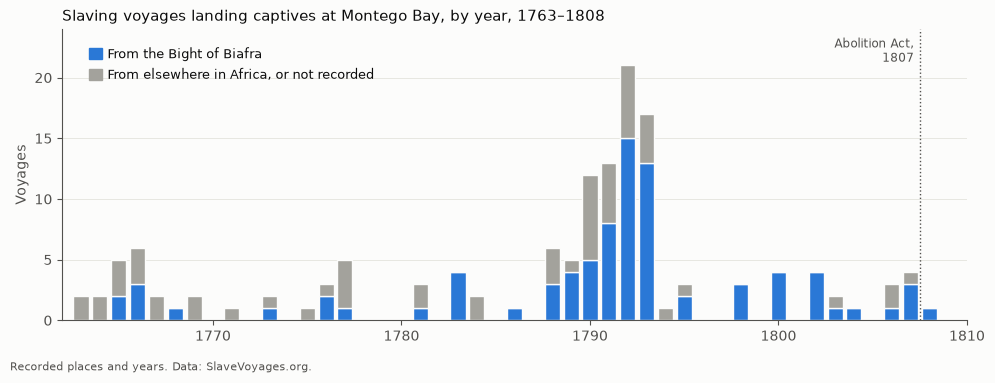

In [12]:
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3dd"
BIAFRA, OTHER = "#2a78d6", "#a3a29c"
plt.rcParams.update(
    {"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "text.color": INK, "font.size": 10}
)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(by_year.index, by_year["Bight of Biafra"], color=BIAFRA, width=0.8, edgecolor=SURFACE)
ax.bar(
    by_year.index, by_year["Other or not recorded"], bottom=by_year["Bight of Biafra"],
    color=OTHER, width=0.8, edgecolor=SURFACE,
)  # fmt: skip
ax.text(1764.4, 21.6, "From the Bight of Biafra", color=INK, fontsize=9)
ax.add_patch(plt.Rectangle((1763.4, 21.5), 0.7, 0.9, color=BIAFRA))
ax.text(1764.4, 19.9, "From elsewhere in Africa, or not recorded", color=INK, fontsize=9)
ax.add_patch(plt.Rectangle((1763.4, 19.8), 0.7, 0.9, color=OTHER))
ax.axvline(1807.5, color=MUTED, linewidth=1, linestyle=":")
ax.text(1807.2, 23.4, "Abolition Act,\n1807", ha="right", va="top", fontsize=8.5, color=MUTED)
ax.set_xlim(1762, 1810)
ax.set_ylim(0, 24)
ax.set_ylabel("Voyages", color=MUTED)
ax.set_title(
    "Slaving voyages landing captives at Montego Bay, by year, 1763–1808",
    loc="left", fontsize=11,
)  # fmt: skip
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color(MUTED)
ax.tick_params(colors=MUTED)
ax.yaxis.grid(True, color=GRID, linewidth=0.6)
ax.set_axisbelow(True)
fig.text(0.01, 0.01, "Recorded places and years. Data: SlaveVoyages.org.", fontsize=8, color=MUTED)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig("figures/09_montego_bay_by_year.png", dpi=200)

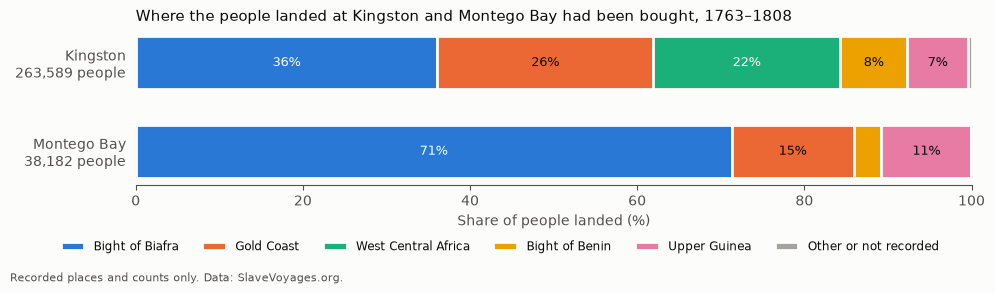

In [13]:
COLOURS = dict(
    zip(ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", OTHER], strict=True)
)
DARK = {"Bight of Biafra", "West Central Africa"}  # white labels only on these fills

fig, ax = plt.subplots(figsize=(10, 2.9))
labels = [f"{p}\n{people.loc[p].sum():,} people" for p in PORTS]
left = pd.Series(0.0, index=PORTS)
for region in ORDER:
    ax.barh(
        labels, mix[region], left=left, color=COLOURS[region], edgecolor=SURFACE,
        linewidth=2, label=region, height=0.6,
    )  # fmt: skip
    for i, port in enumerate(PORTS):
        if mix.loc[port, region] >= 7:
            ax.text(
                left[port] + mix.loc[port, region] / 2, i, f"{mix.loc[port, region]:.0f}%",
                ha="center", va="center", fontsize=9,
                color=SURFACE if region in DARK else INK,
            )  # fmt: skip
    left += mix[region]
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of people landed (%)", color=MUTED)
ax.set_title(
    "Where the people landed at Kingston and Montego Bay had been bought, 1763–1808",
    loc="left", fontsize=11,
)  # fmt: skip
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color(MUTED)
ax.tick_params(colors=MUTED, left=False)
fig.legend(frameon=False, fontsize=8.5, ncol=6, loc="lower center", bbox_to_anchor=(0.5, 0.07))
fig.text(
    0.01, 0.01, "Recorded places and counts only. Data: SlaveVoyages.org.", fontsize=8,
    color=MUTED,
)  # fmt: skip
fig.tight_layout(rect=(0, 0.14, 1, 1))
fig.savefig("figures/09_kingston_montego_origins.png", dpi=200)

## Runaways and landings, on recorded figures

Notebook 07 compared runaway notices with landings using imputed numbers. The same
comparison here uses recorded landings: people landed at Kingston and Montego Bay with a
recorded year in 1763–1795 (Montego Bay's first landings to the last notice in the
*Cornwall Chronicle*). Runaways: *Fugitives from Slavery in Jamaica* (Enslaved.org, CC BY
4.0), African-born people with a region of origin, grouped as in notebook 07.

In [14]:
GROUPS = ORDER[:5]
ORIGIN_GROUP = {
    "Bight of Biafra": "Bight of Biafra",
    "Gold Coast": "Gold Coast",
    "West Central Africa": "West Central Africa",
    "Bight of Benin": "Bight of Benin",
    "Greater Senegambia": "Upper Guinea",
}
PAPER_PORT = {
    "Cornwall Chronicle": "Montego Bay",
    "Jamaica Mercury": "Kingston",
    "Royal Gazette": "Kingston",
}
runaways = v.sql(
    """
    SELECT DISTINCT p.person_id, p.ethnonym_place_of_origin AS origin,
           s.source_title AS newspaper
    FROM enslaved_people p
    JOIN enslaved_roles r ON r.person_id = p.person_id AND r.participant_role = 'Runaway'
    JOIN enslaved_record_sources rs ON rs.record_id = p.person_id
    JOIN enslaved_sources s ON s.source_id = rs.source_id
    JOIN enslaved_projects pr ON pr.project_id = s.project_id
    WHERE pr.project_code = 'FSJ' AND s.source_title NOT LIKE 'Chambers%'
    """
).to_pandas()
assert runaways.person_id.is_unique
runaways = runaways.assign(
    group=runaways.origin.map(ORIGIN_GROUP), port=runaways.newspaper.map(PAPER_PORT)
).dropna(subset=["group", "port"])
run_counts = pd.crosstab(runaways.group, runaways.port).reindex(GROUPS)[PORTS].fillna(0)
run_share = (run_counts / run_counts.sum() * 100).round(1)

early = known[known.year.between(1763, 1795) & known.region.isin(GROUPS)]
land = (
    early.pivot_table(
        index="region", columns="port", values="landed", aggfunc="sum", observed=False
    )
    .reindex(GROUPS)[PORTS]
    .fillna(0)
)  # fmt: skip
land_share = (land / land.sum() * 100).round(1)


def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    """95% Wilson score interval for k/n, in per cent."""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return round((centre - half) * 100, 1), round((centre + half) * 100, 1)


side = pd.concat(
    {
        "runaways (%)": run_share,
        "landed, recorded (%)": land_share,
    },
    axis=1,
)
side

runaways (%)             landed, recorded (%)            
port                    Kingston Montego Bay             Kingston Montego Bay
Bight of Biafra             16.9        37.0                 26.6        67.7
Gold Coast                  20.8        19.0                 35.8        16.0
West Central Africa         28.6        20.8                 16.5         0.0
Bight of Benin               3.9         6.0                 11.1         4.0
Upper Guinea                29.9        17.1                 10.0        12.3

In [15]:
n_run = run_counts.sum().astype(int)
n_land = land.sum().astype(int)
n_run.to_dict(), n_land.to_dict()

({'Kingston': 77, 'Montego Bay': 216},
 {'Kingston': 150208, 'Montego Bay': 31233})

The recorded figures tell the same story as notebook 07: the Bight of Biafra is the largest
group among the Montego Bay runaways and much smaller among Kingston's, and the gap between
ports is wider for landings than for runaways.

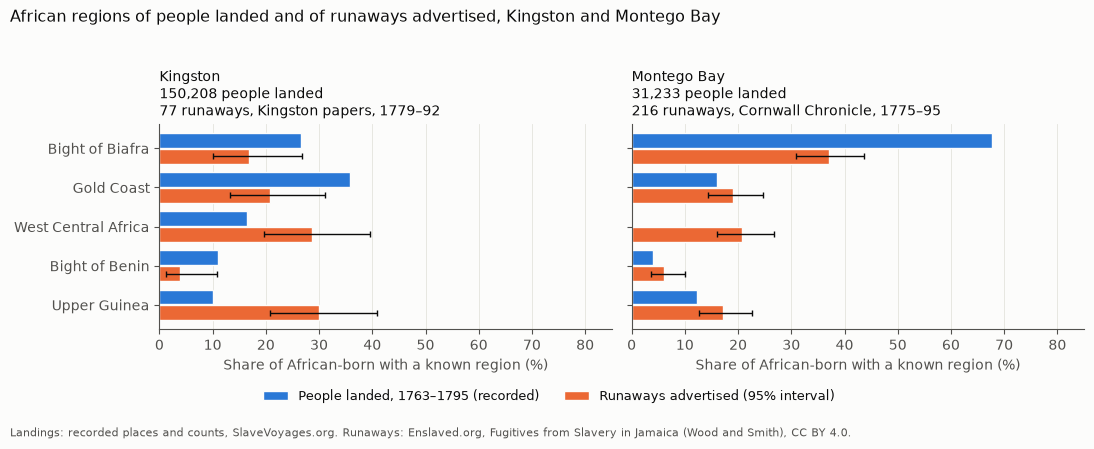

In [16]:
LANDED, RAN = "#2a78d6", "#eb6834"
PAPERS = {"Kingston": "Kingston papers, 1779–92", "Montego Bay": "Cornwall Chronicle, 1775–95"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, port in zip(axes, PORTS, strict=True):
    y = range(len(GROUPS))
    ax.barh(
        [i - 0.2 for i in y], land_share[port], height=0.38, color=LANDED,
        edgecolor=SURFACE, linewidth=1, label="People landed, 1763–1795 (recorded)",
    )  # fmt: skip
    ax.barh(
        [i + 0.2 for i in y], run_share[port], height=0.38, color=RAN, edgecolor=SURFACE,
        linewidth=1, label="Runaways advertised (95% interval)",
    )  # fmt: skip
    ci = [wilson(int(run_counts.loc[g, port]), int(n_run[port])) for g in GROUPS]
    ax.errorbar(
        run_share[port], [i + 0.2 for i in y],
        xerr=[
            [r - lo for r, (lo, _) in zip(run_share[port], ci, strict=True)],
            [hi - r for r, (_, hi) in zip(run_share[port], ci, strict=True)],
        ],
        fmt="none", ecolor=INK, elinewidth=1, capsize=2,
    )  # fmt: skip
    ax.set_title(
        f"{port}\n{n_land[port]:,} people landed\n{n_run[port]} runaways, {PAPERS[port]}",
        loc="left", fontsize=10,
    )  # fmt: skip
    ax.set_yticks(list(y), GROUPS)
    ax.set_xlim(0, 85)
    ax.set_xlabel("Share of African-born with a known region (%)", color=MUTED)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(MUTED)
    ax.tick_params(colors=MUTED)
    ax.xaxis.grid(True, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
axes[0].invert_yaxis()  # shared y axis: invert once
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False, fontsize=9,
           bbox_to_anchor=(0.5, 0.06))  # fmt: skip
fig.suptitle(
    "African regions of people landed and of runaways advertised, Kingston and Montego Bay",
    x=0.01, ha="left", fontsize=11.5,
)  # fmt: skip
fig.text(
    0.01, 0.01,
    "Landings: recorded places and counts, SlaveVoyages.org. Runaways: Enslaved.org, "
    "Fugitives from Slavery in Jamaica (Wood and Smith), CC BY 4.0.",
    fontsize=8, color=MUTED,
)  # fmt: skip
fig.tight_layout(rect=(0, 0.12, 1, 0.95))
fig.savefig("figures/09_runaways_vs_landings_recorded.png", dpi=200)

## What this can and cannot support

- **The landing port is not where people lived** (see notebooks 06 and 07). The runaway
  notices in notebook 07 point the same way for the north-west: the Bight of Biafra is the
  largest group among African-born runaways in the Montego Bay paper (37%) and much smaller
  in the Kingston papers (17%).
- **The voyages end 23 years before the rebellion.** Many of the people who rose in 1831
  were born in Jamaica. The data shows who was landed in the north-west, not who took part
  in 1831. The African-born share of St James's population in the 1817–1832 registers is a
  question for the historian reviewing the piece; it is not in this database.
- **Recorded counts miss some voyages.** The recorded total is a floor; the imputed total
  above is SlaveVoyages' estimate, licensed CC BY-NC.

## Checks

In [17]:
# Checked 2026-10-20 on https://legacy.slavevoyages.org/voyage/database, filter: principal
# place where captives were landed = Montego Bay. Same 144 voyage IDs; 133 with "Captives
# arrived at 1st port", summing to 40,050. Summary statistics: 47,563 embarked (imputed,
# equal) and 43,261 disembarked (imputed; ours 43,263, the site's data is newer).
assert (mb_voyages, mb_with_count, mb_people, mb_no_year) == (144, 133, 40_050, 2)
assert (montego.year.min(), montego.year.max()) == (1763, 1808)
assert len(montego) == 142
assert people.sum(axis=1).tolist() == [263_589, 38_182]
assert known.groupby("port").size().tolist() == [835, 124]
assert mix.loc["Montego Bay", "Bight of Biafra"] == 71.3
assert mix.loc["Kingston", "Bight of Biafra"] == 36.1
assert 18 <= mix.loc["Kingston", "West Central Africa"] <= 23
assert mix.loc["Montego Bay", "West Central Africa"] == 0
assert african_ports.index[0] == "Bonny"
assert african_ports.voyages.iloc[:4].tolist() == [53, 14, 10, 9]
assert african_ports.index[:4].tolist() == [
    "Bonny",
    "New Calabar",
    "Anomabu, Adja, Agga",
    "Calabar",
]
assert home_ports.iloc[:3].tolist() == [88, 28, 18]
assert by_decade.loc[1790, "people_landed"] == 20_574
assert last.landed == 161 and last.region == "Bight of Biafra"
assert {"New Calabar", "Calabar"} <= set(african_ports.index)
assert home_ports.index[:2].tolist() == ["Liverpool", "Bristol"]
assert by_year.sum(axis=1).max() == 21 < 24  # fits the y axis
assert by_year.sum(axis=1).nlargest(2).index.tolist() == [1792, 1793]
assert by_decade.voyages.idxmax() == 1790 and by_decade.loc[1790, "voyages"] == 70
assert (last.ship_name, last.home_port, last.year) == ("Ruby", "Liverpool", 1808)
assert (queen.ship_name, queen.principal_purchase_place_name) == ("African Queen", "Calabar")
assert (queen.departure_place_name, str(queen.first_landing_date)[:7]) == ("Bristol", "1793-01")
assert (queen.captives_on_board_leaving_africa, queen.captives_arrived_first_landing) == (330, 214)
assert pd.isna(queen.captives_died_middle_passage)
queen_sexed = [queen[f"{g}_embarked_first_port"] for g in ("men", "women", "boys", "girls")]
assert queen_sexed == [93, 138, 10, 14] and sum(queen_sexed) == 255
# Values on https://legacy.slavevoyages.org/voyage/18129/variables (checked 2026-10-20)
assert [queen.captain_1, queen.captain_2, queen.captain_3] == [
    "Stribling, Samuel",
    "Forsyth, Hamet",
    "Lloyd, James",
]
assert (queen.owner_1, queen.construction_place_name, queen.year_constructed) == (
    "Rogers, James",
    "Folkstone",
    1780,
)
assert (queen.tonnage, queen.guns) == (277, 6)
assert (str(queen.departure_date)[:10], str(queen.first_landing_date)[:10]) == (
    "1792-01-16",
    "1793-01-18",
)
assert str(queen.completed_date)[:10] == "1793-05-06"
assert (queen.crew_outset, queen.crew_first_landing) == (37, 18)
assert queen.died_middle_passage_imputed == 116  # imputed, not recorded
assert imputed_total == 43_263
assert biafra_coasts.voyages.to_dict() == {"Gabon": 3, "Nigeria": 76, "Port not named": 7}
assert biafra_coasts.loc["Nigeria", "people_landed"] == 25_772
assert "Cameroon" not in biafra_coasts.index
assert (n_run.tolist(), n_land.tolist()) == ([77, 216], [150_208, 31_233])
assert run_share.loc["Bight of Biafra"].tolist() == [16.9, 37.0]  # as in notebook 07
assert land_share.loc["Bight of Biafra"].tolist() == [26.6, 67.7]
assert land_share.loc["West Central Africa", "Montego Bay"] == 0
assert run_share.loc["West Central Africa", "Montego Bay"] > 19
assert wilson(80, 216)[0] > wilson(13, 77)[1]  # runaway intervals do not overlap
assert run_counts.loc["Bight of Biafra"].tolist() == [13, 80]

In [18]:
print(voyages.citation())

SlaveVoyages, Trans-Atlantic Slave Trade Database, https://www.slavevoyages.org (accessed October 20, 2026).
